In [1]:
%load_ext autoreload
%autoreload 2
import data.GradualePipeline as gs
from models.mm_music_components_region_mode import MelodicComponentsRegionModeModel
data_mode = gs.GradualePipeline.load("data/processed/trope_dataset_pitches_modes.pkl")
len(data_mode['x_0_obs'])

528

In [2]:

model = MelodicComponentsRegionModeModel()
trace = model.fit(data_mode, use_latest=True, draws=1000, tune=500, description="First_try_tropes")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [base_logits, w_interval, w_register, w_repeat, w_direction, register_center, pi, nu]


Output()

ValueError: Not enough samples to build a trace.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import arviz as az
from pathlib import Path
from matplotlib.lines import Line2D



def _extract_summary_stats(idata, var_name):
    posterior = idata.posterior[var_name]
    mean_vals = posterior.mean(dim=["chain", "draw"]).values
    std_vals = posterior.std(dim=["chain", "draw"]).values
    return mean_vals, std_vals

def _generate_pitch_labels(v_size):
    base_notes = ["A", "B", "C", "D", "E", "F", "G"]
    labels = []
    for i in range(v_size):
        octave = i // 7
        note = base_notes[i % 7]
        if octave == 0:
            labels.append(note)
        else:
            labels.append(note.lower() * octave)
    return labels


def plot_custom_musical_weights_forest(idata, r_labels=None, m_labels=None, group_by="mode"):
    expected_weights = ["w_interval", "w_register", "w_repeat", "w_direction"]
    present_weights = [w for w in expected_weights if w in idata.posterior]
    
    if not present_weights:
        print("Keine musikalischen Gewichte gefunden.")
        return None

    try:
        R = idata.posterior[present_weights[0]].shape[2]
        M = idata.posterior[present_weights[0]].shape[3]
    except IndexError:
        print("Modell ist nicht hierarchisch, Fallback wird benötigt.")
        return None

    r_labels = r_labels or [f"Region {i}" for i in range(R)]
    m_labels = m_labels or [f"Mode {i}" for i in range(M)]

    mode_colors = sns.color_palette("husl", M)
    shade_factors = np.linspace(0.0, 0.65, len(present_weights))

    def get_shade(base_color, factor):
        c = np.array(mcolors.to_rgb(base_color))
        mixed = c + (np.array([1, 1, 1]) - c) * factor
        return mcolors.to_hex(mixed)

    fig, ax = plt.subplots(figsize=(12, len(present_weights) * M * R * 0.35 + 4))

    y_pos = 0
    y_ticks = []
    y_labels = []

    for w_idx, weight in enumerate(present_weights):
        post = idata.posterior[weight]
        mean_vals = post.mean(dim=["chain", "draw"]).values
        hdi_vals = az.hdi(post, hdi_prob=0.94)[weight].values

        ax.text(0.01, y_pos, f"COMPONENT: {weight.upper()}", fontsize=12, fontweight='bold', ha='left', va='center', transform=ax.get_yaxis_transform())
        y_pos -= 1.2

        if group_by == "mode":
            for m in range(M):
                color = get_shade(mode_colors[m], shade_factors[w_idx])
                for r in range(R):
                    val = mean_vals[r, m]
                    hdi_low = hdi_vals[r, m, 0]
                    hdi_high = hdi_vals[r, m, 1]

                    ax.errorbar(
                        val, y_pos, xerr=[[val - hdi_low], [hdi_high - val]],
                        fmt='o', color=color, capsize=4, linewidth=3, markersize=7
                    )

                    y_ticks.append(y_pos)
                    y_labels.append(f"{m_labels[m]} - {r_labels[r]}")
                    y_pos -= 0.5
                y_pos -= 0.4
        else:
            for r in range(R):
                for m in range(M):
                    color = get_shade(mode_colors[m], shade_factors[w_idx])
                    val = mean_vals[r, m]
                    hdi_low = hdi_vals[r, m, 0]
                    hdi_high = hdi_vals[r, m, 1]

                    ax.errorbar(
                        val, y_pos, xerr=[[val - hdi_low], [hdi_high - val]],
                        fmt='o', color=color, capsize=4, linewidth=3, markersize=7
                    )

                    y_ticks.append(y_pos)
                    y_labels.append(f"{r_labels[r]} - {m_labels[m]}")
                    y_pos -= 0.5
                y_pos -= 0.4
                
        y_pos -= 1.2

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels, fontsize=10)
    ax.axvline(0, color="black", linestyle="--", alpha=0.5)

    legend_elements = [Line2D([0], [0], color=mode_colors[m], lw=6, label=m_labels[m]) for m in range(M)]
    legend_elements.append(Line2D([0], [0], color='w', lw=0, label=""))
    legend_elements.append(Line2D([0], [0], color='w', lw=0, label="Shades (Dark→Light):"))
    
    for w_idx, w in enumerate(present_weights):
        legend_elements.append(Line2D([0], [0], color=get_shade('gray', shade_factors[w_idx]), lw=6, label=w))

    ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.35, 1), title="Legend", borderpad=1)

    ax.set_title("Posterior Distributions of Musical Rule Weights", fontsize=16, pad=20)
    ax.set_xlabel("Weight Value (Positive = applies strongly | Negative = inverse)")
    ax.grid(axis='x', linestyle=':', alpha=0.6)

    plt.tight_layout()
    return fig


def plot_detailed_regional_comparison(idata, r_labels, m_labels):
    expected_weights = ["w_interval", "w_register", "w_repeat", "w_direction"]
    present_weights = [w for w in expected_weights if w in idata.posterior]
    
    if not present_weights:
        return None
        
    num_weights = len(present_weights)
    fig, axes = plt.subplots(num_weights, 1, figsize=(12, 4 * num_weights), sharex=True)
    if num_weights == 1:
        axes = [axes]
        
    modes_x = np.arange(len(m_labels))
    width = 0.2 
    
    colors = ["#1f77b4", "#ff7f0e", "#2ca02c"] 
    
    for ax, weight in zip(axes, present_weights):
        post = idata.posterior[weight]
        
        if len(post.shape) < 4:
            continue
            
        mean_vals = post.mean(dim=["chain", "draw"]).values
        hdi_vals = az.hdi(post, hdi_prob=0.94)[weight].values
        
        offsets = [-width, 0, width]
        if len(r_labels) != 3:
            offsets = np.linspace(-width, width, len(r_labels))

        for r_idx, r_name in enumerate(r_labels):
            x_pos = modes_x + offsets[r_idx]
            y_mean = mean_vals[r_idx, :]
            
            y_err_lower = y_mean - hdi_vals[r_idx, :, 0]
            y_err_upper = hdi_vals[r_idx, :, 1] - y_mean
            
            ax.errorbar(
                x_pos, 
                y_mean, 
                yerr=[y_err_lower, y_err_upper], 
                fmt='o', 
                label=r_name, 
                color=colors[r_idx % len(colors)],
                markersize=6,
                capsize=4,
                elinewidth=2,
                alpha=0.8
            )
            
        ax.set_title(f"Comparison of '{weight}' across Modes and Regions")
        ax.set_ylabel("Weight Value")
        ax.axhline(0, color="black", linestyle="--", alpha=0.3)
        ax.grid(axis='y', linestyle=':', alpha=0.6)
        
        if ax == axes[0]:
            ax.legend(title="Regions", bbox_to_anchor=(1.05, 1), loc='upper left')

    axes[-1].set_xticks(modes_x)
    axes[-1].set_xticklabels(m_labels)
    axes[-1].set_xlabel("Modes")
    
    plt.tight_layout()
    return fig


def plot_register_center_forest(idata, v_size):
    if "register_center" not in idata.posterior:
        return None
        
    v_labels = _generate_pitch_labels(v_size)
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    az.plot_forest(
        idata,
        var_names=["register_center"],
        combined=True,
        hdi_prob=0.94,
        ax=ax,
        colors="indigo"
    )
    
    ax.set_xlim(0, v_size - 1)
    ax.set_xticks(range(v_size))
    ax.set_xticklabels(v_labels)
    
    ax.set_title("Learned Gravitational Center of the Melodies (Register Center)", fontsize=14)
    ax.set_xlabel("Pitch")
    
    plt.tight_layout()
    return fig


def plot_weight_differences(idata, weight_name="w_interval", region_a=0, region_b=1, mode_idx=0, r_labels=None, m_labels=None):
    if weight_name not in idata.posterior:
        raise ValueError(f"{weight_name} nicht im Trace gefunden.")
        
    post = idata.posterior[weight_name]
    
    if len(post.shape) < 4: 
        raise ValueError("Dieses Modell scheint keine Regionen und Modi zu beinhalten.")

    samples_a = post[:, :, region_a, mode_idx].values.flatten()
    samples_b = post[:, :, region_b, mode_idx].values.flatten()
    
    diff = samples_a - samples_b
    
    reg_a_name = r_labels[region_a] if r_labels else f"Region {region_a}"
    reg_b_name = r_labels[region_b] if r_labels else f"Region {region_b}"
    mode_name = m_labels[mode_idx] if m_labels else f"Mode {mode_idx}"

    fig, ax = plt.subplots(figsize=(8, 5))
    
    sns.kdeplot(diff, fill=True, color="darkred", ax=ax, alpha=0.6)
    
    mean_diff = np.mean(diff)
    hdi = az.hdi(diff, hdi_prob=0.94)
    
    ax.axvline(mean_diff, color="black", linestyle="-", label=f"Mean Diff: {mean_diff:.2f}")
    ax.axvline(hdi[0], color="black", linestyle=":", alpha=0.7, label="94% HDI")
    ax.axvline(hdi[1], color="black", linestyle=":", alpha=0.7)
    ax.axvline(0, color="green", linestyle="--", linewidth=2, label="Zero Difference")
    
    ax.set_title(f"Difference in '{weight_name}'\n{reg_a_name} vs {reg_b_name} ({mode_name})", fontsize=12)
    ax.set_xlabel(f"Difference ({reg_a_name} minus {reg_b_name})")
    ax.set_ylabel("Density")
    ax.legend()
    
    plt.tight_layout()
    return fig


def plot_base_logits_hierarchical(idata, v_size, region_idx=0, m_labels=None, r_labels=None):
    if "base_logits" not in idata.posterior:
        print("Keine base_logits gefunden.")
        return None
        
    v_labels = _generate_pitch_labels(v_size)
    mean_vals = idata.posterior["base_logits"].mean(dim=["chain", "draw"]).values
    
    # Automatische Anpassung an die Hierarchie (4D = Region x Mode x V x V)
    shape = mean_vals.shape
    if len(shape) == 4:
        M = shape[1]
        plot_data = mean_vals[region_idx]
        region_name = r_labels[region_idx] if r_labels else f"Region {region_idx}"
    elif len(shape) == 3:  # Nur Modi
        M = shape[0]
        plot_data = mean_vals
        region_name = "Global"
    elif len(shape) == 2:  # Globales Modell
        M = 1
        plot_data = np.expand_dims(mean_vals, axis=0)
        region_name = "Global"
    else:
        return None

    m_labels = m_labels or [f"Mode {m}" for m in range(M)]
    
    # Figure anzahl der Modi anpassen
    base_size = max(5.0, v_size * 0.4)
    fig, axes = plt.subplots(1, M, figsize=(base_size * M, base_size + 1))
    if M == 1: 
        axes = [axes]
        
    for m, ax in enumerate(axes):
        sns.heatmap(
            plot_data[m],
            cmap="vlag",  # vlag ist perfekt für Logits, die um 0 zentriert sind (Rot = Positiv, Blau = Negativ)
            center=0,
            ax=ax,
            xticklabels=v_labels,
            yticklabels=v_labels,
            square=True,
           # cbar_kws={"label": "Unscaled Base Logit"} if m == M-1 else False
        )
        
        title = f"{m_labels[m]}\n({region_name})"
        ax.set_title(title, pad=10)
        ax.set_xlabel("To Pitch (t)")
        if m == 0:
            ax.set_ylabel("From Pitch (t-1)")
            
    plt.suptitle("Base Logits (Remaining Motif Preferences after global Rules)", fontsize=16, y=1.05)
    plt.tight_layout()
    return fig

def export_all_component_plots(idata, v_size, r_labels=None, m_labels=None, save_dir="visual/components", group_forest_by="mode"):
    save_path = Path(save_dir)
    save_path.mkdir(parents=True, exist_ok=True)
    
    r_labels = r_labels or ["West", "East", "Italy"]
    m_labels = m_labels or [f"Mode {m}" for m in range(1, 9)]
    
    figs = {
        "all_musical_weights": plot_custom_musical_weights_forest(idata, r_labels, m_labels, group_by=group_forest_by),
        "detailed_regional_comparison": plot_detailed_regional_comparison(idata, r_labels, m_labels),
        "register_centers": plot_register_center_forest(idata, v_size),
      
    }
    base_logits = {f"base_logits_region_{i}": plot_base_logits_hierarchical(idata, v_size, region_idx=i) for i in range(3)}
    figs = figs | base_logits
    try:
        figs["diff_w_interval_west_vs_italy"] = plot_weight_differences(
            idata, "w_interval", region_a=0, region_b=2, mode_idx=0, r_labels=r_labels, m_labels=m_labels
        )
    except ValueError:
        pass
        
    for name, fig in figs.items():
        if fig is not None:
            file_path = save_path / f"{name}.png"
            fig.savefig(file_path, bbox_inches="tight", dpi=200)

            
    print(f"Plots erfolgreich gespeichert in: {save_path.absolute()}")
    return figs

In [2]:
data_region = gs.GradualePipeline.load("data/processed/trope_dataset_pitches_modes_regions.pkl")

model_region = MelodicComponentsRegionModeModel()
trace_region = model_region.fit(data_region, use_latest=True, draws=500, tune=300, description="First_try_trope_region")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [base_logits, w_interval, w_register, w_repeat, w_direction, register_center, pi, nu_global, kappa, nu]


Output()

Sampling 4 chains for 300 tune and 500 draw iterations (1_200 + 2_000 draws total) took 26041 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


Plots erfolgreich gespeichert in: /Users/timeipert/PycharmProjects/generative_medieval_music_model/visual/components_region


{'all_musical_weights': <Figure size 1200x3760 with 1 Axes>,
 'detailed_regional_comparison': <Figure size 1200x1600 with 4 Axes>,
 'register_centers': <Figure size 1000x600 with 1 Axes>,
 'base_logits_region_0': <Figure size 5760x820 with 16 Axes>,
 'base_logits_region_1': <Figure size 5760x820 with 16 Axes>,
 'base_logits_region_2': <Figure size 5760x820 with 16 Axes>,
 'diff_w_interval_west_vs_italy': <Figure size 800x500 with 1 Axes>}

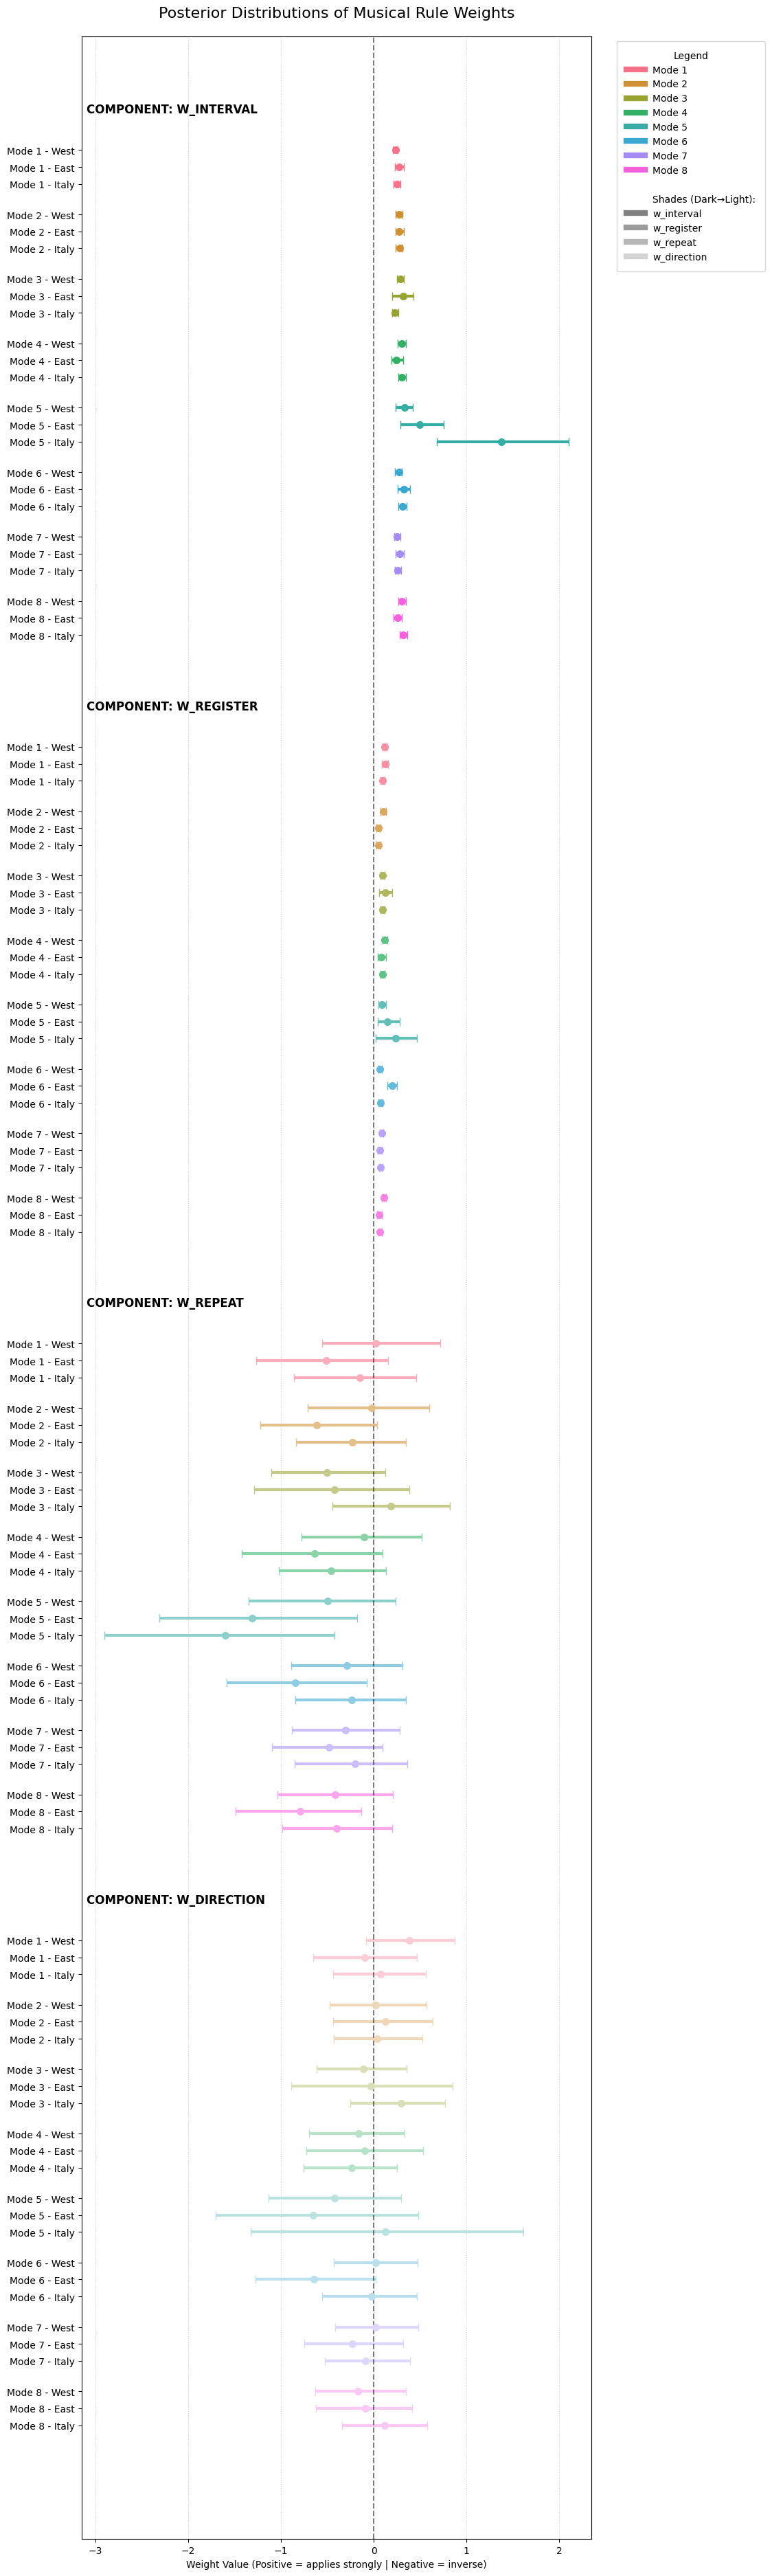

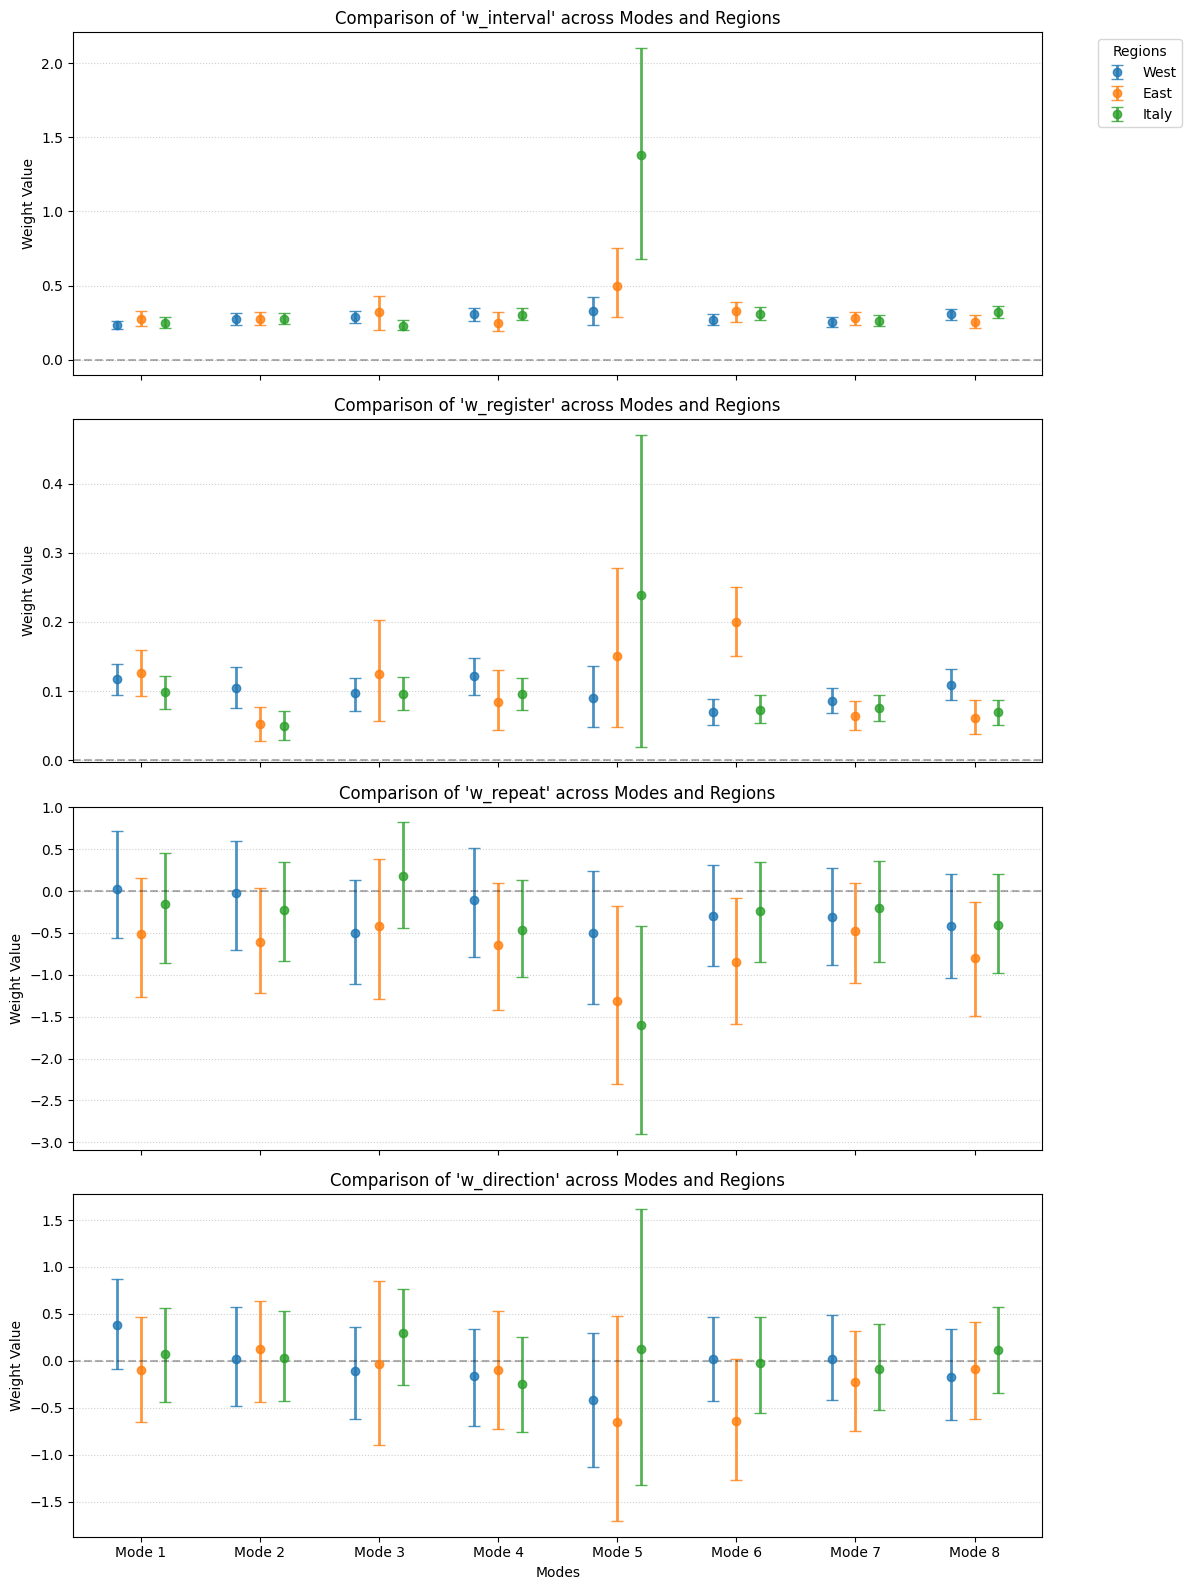

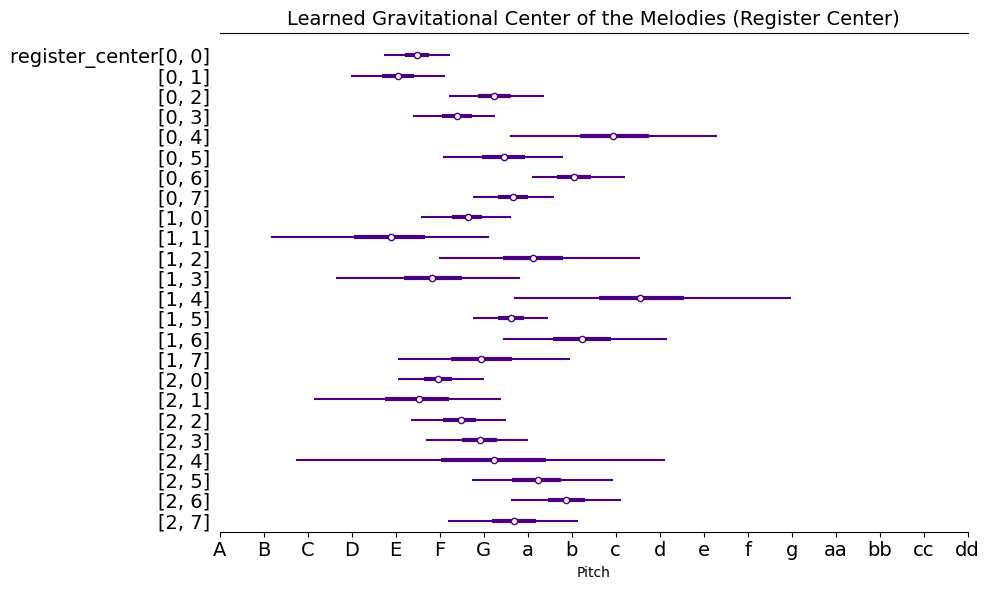

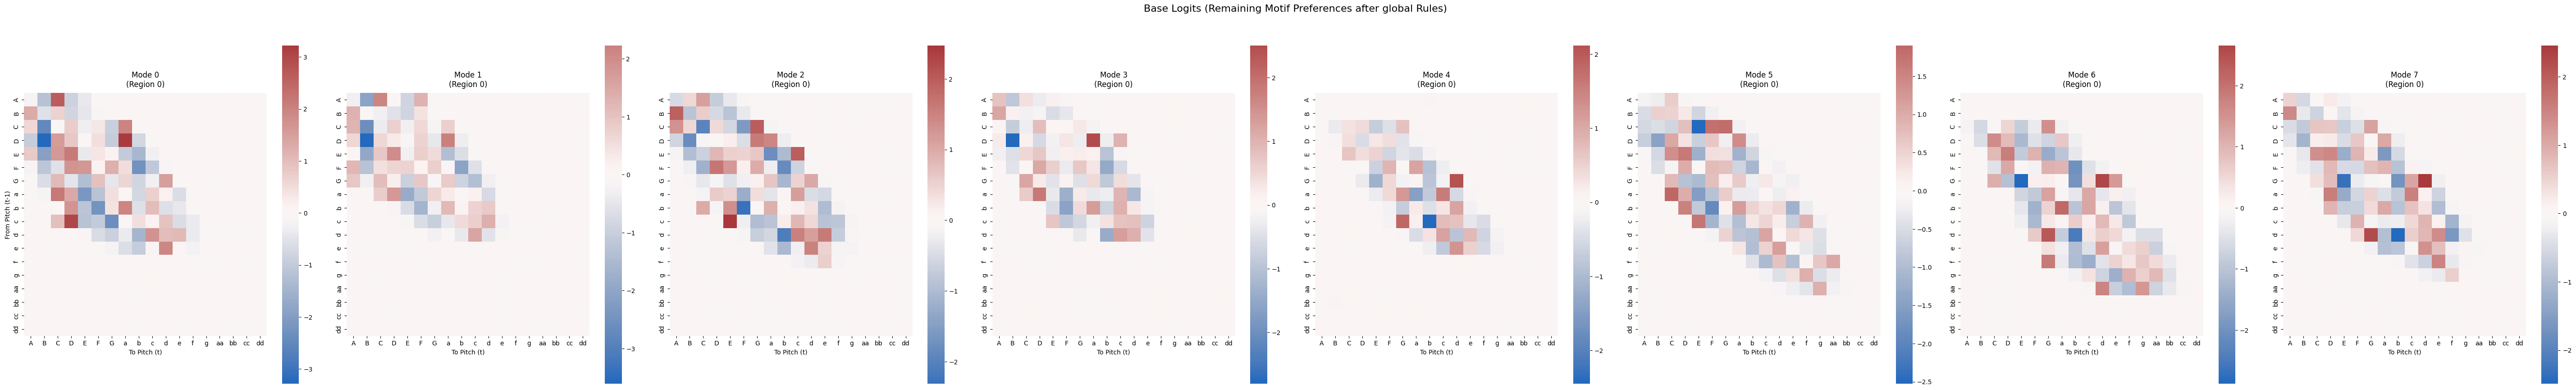

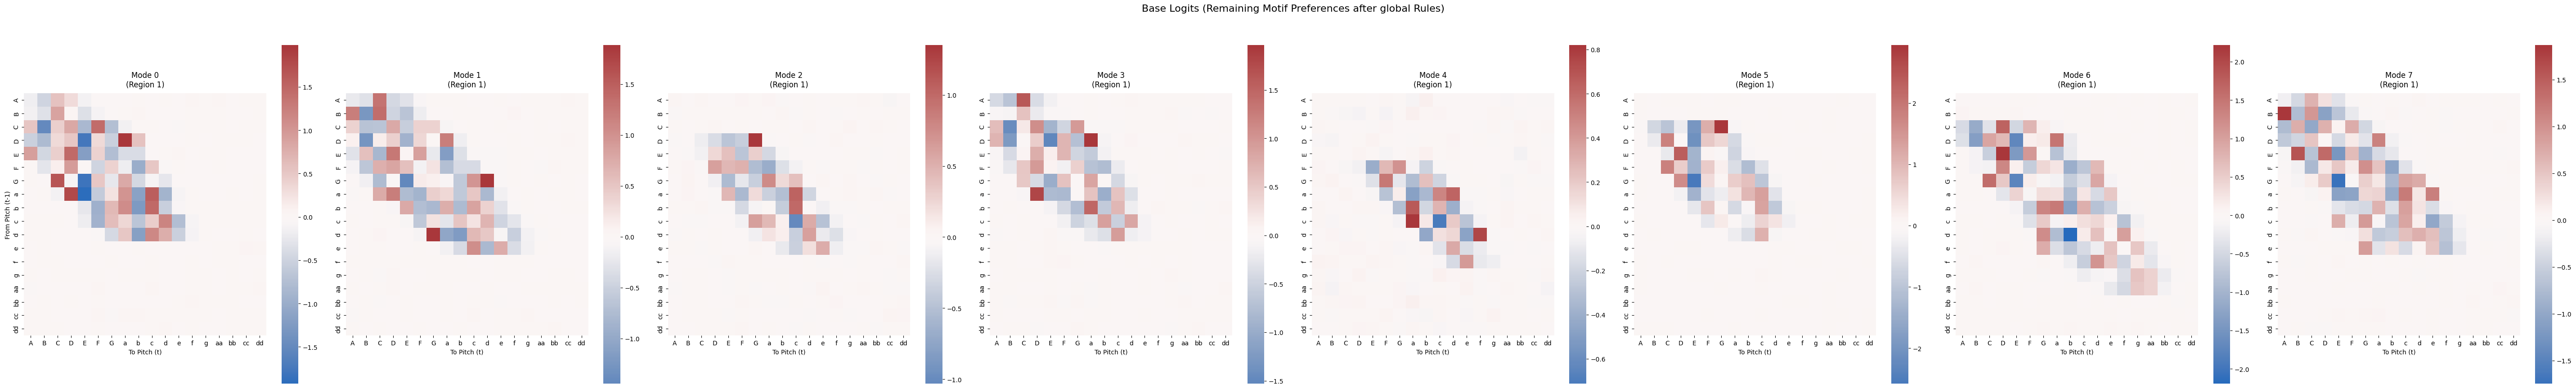

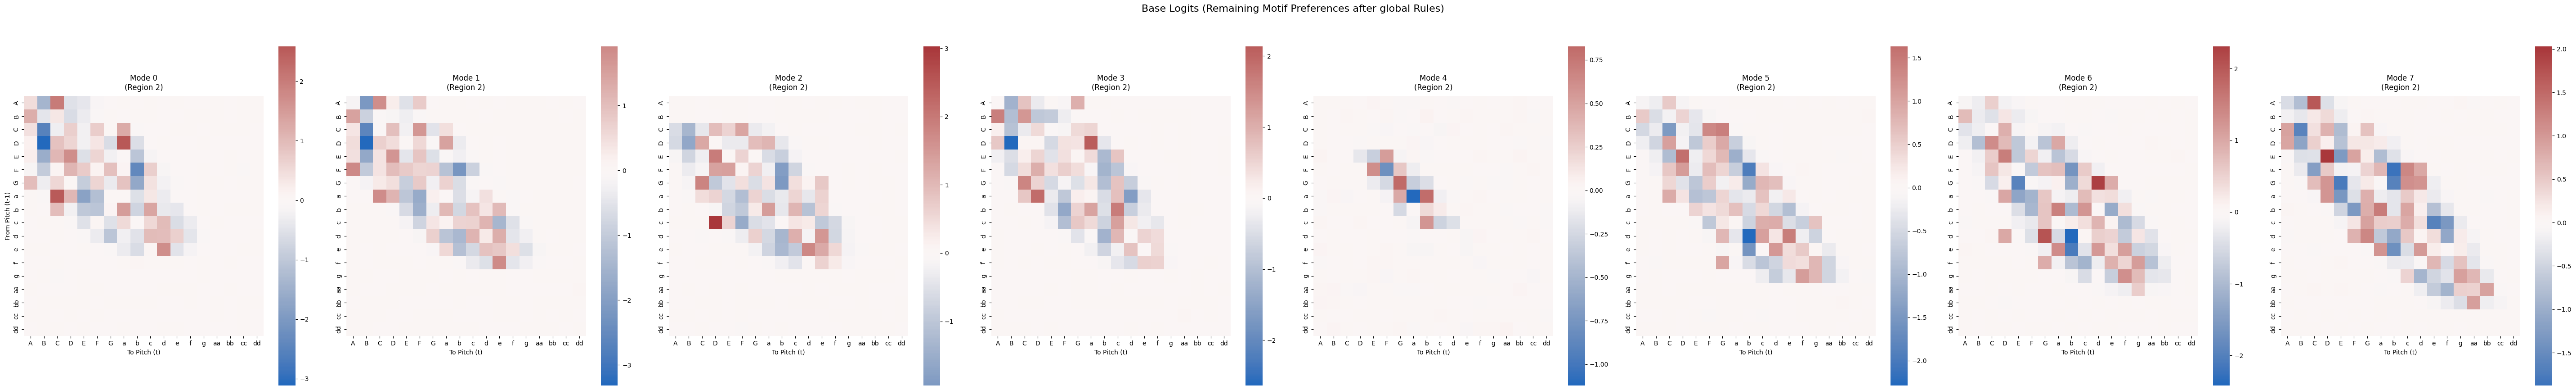

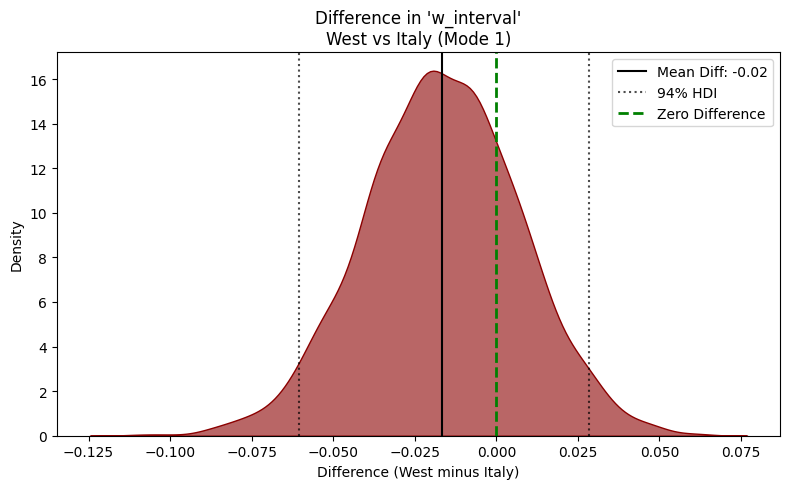

In [5]:
export_all_component_plots(trace_region, len(model_region.alphabet), save_dir="visual/components_region/")

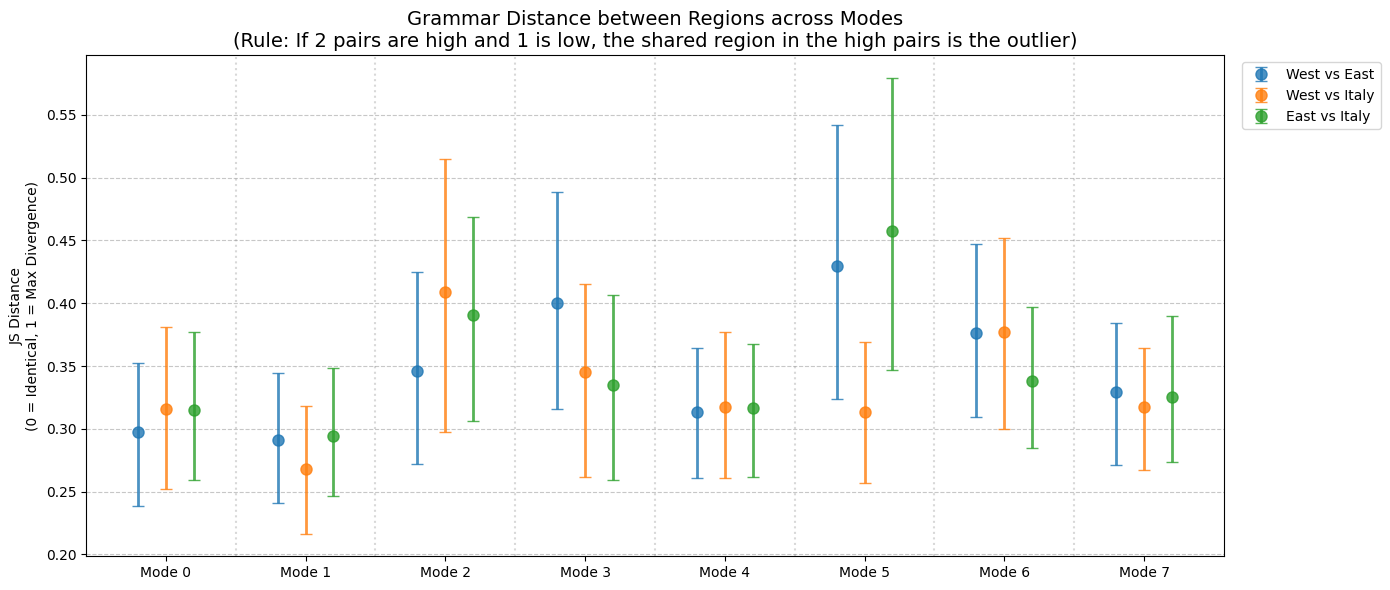

In [49]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import arviz as az
from scipy.spatial.distance import jensenshannon


def plot_jsd_categorical_with_uncertainty(idata, r_labels=None, m_labels=None):
    """
    Kategorischer Distanz-Plot OHNE verwirrende Linien zwischen den Modi.
    """
    A_post = idata.posterior["A"].stack(sample=("chain", "draw"))
    A_samples = A_post.transpose("sample", ...).values
    samples, R, M, _, _ = A_samples.shape

    r_labels = r_labels or [f"Region {r}" for r in range(R)]
    m_labels = m_labels or [f"Mode {m}" for m in range(M)]

    fig, ax = plt.subplots(figsize=(14, 6))

    pairs = [(0, 1), (0, 2), (1, 2)]
    colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
    A_flat = A_samples.reshape(samples, R, M, -1)

    modes_x = np.arange(M)
    width = 0.2  

    for idx, (r_a, r_b) in enumerate(pairs):
        pair_label = f"{r_labels[r_a]} vs {r_labels[r_b]}"
        jsd_means = np.zeros(M)
        jsd_hdi = np.zeros((M, 2))

        for m in range(M):
            p = A_flat[:, r_a, m, :]
            q = A_flat[:, r_b, m, :]
            js_dist = jensenshannon(p, q, axis=1)

            jsd_means[m] = np.mean(js_dist)
            jsd_hdi[m] = az.hdi(js_dist, hdi_prob=0.94)

        x_pos = modes_x + (idx - 1) * width
        y_err_lower = jsd_means - jsd_hdi[:, 0]
        y_err_upper = jsd_hdi[:, 1] - jsd_means

        # WICHTIG: linestyle='none' verhindert das Zeichnen von Linien zwischen den Modi!
        ax.errorbar(
            x_pos, jsd_means, yerr=[y_err_lower, y_err_upper],
            fmt='o', linestyle='none', linewidth=2, capsize=4, 
            color=colors[idx], label=pair_label, alpha=0.8, markersize=8
        )

    ax.set_xticks(modes_x)
    ax.set_xticklabels(m_labels)
    ax.set_title("Grammar Distance between Regions across Modes\n(Rule: If 2 pairs are high and 1 is low, the shared region in the high pairs is the outlier)", fontsize=14)
    ax.set_ylabel("JS Distance\n(0 = Identical, 1 = Max Divergence)")
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Vertikale Trennlinien für die Übersichtlichkeit
    for m in range(M - 1):
        ax.axvline(m + 0.5, color='gray', linestyle=':', alpha=0.3)
        
    ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
    plt.tight_layout()
    return fig


fig1 = plot_jsd_categorical_with_uncertainty(trace_region, r_labels=["West", "East", "Italy"])